### Analytics Question
- #### Are there meaningful differences in ICU mortality across hospitals? 
- #### What are the potential factors in hospitals associated with these differences? 

In [73]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
import warnings

warnings.filterwarnings('ignore')

In [ ]:
patient_df = pd.read_csv("/patient.csv.gz")
hospital_df = pd.read_csv("/hospital.csv.gz")
apr_df = pd.read_csv("/apachePatientResult.csv.gz")

### Patient EDA 

In [3]:
patient_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200859 entries, 0 to 200858
Data columns (total 29 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   patientunitstayid          200859 non-null  int64  
 1   patienthealthsystemstayid  200859 non-null  int64  
 2   gender                     200725 non-null  object 
 3   age                        200764 non-null  object 
 4   ethnicity                  198569 non-null  object 
 5   hospitalid                 200859 non-null  int64  
 6   wardid                     200859 non-null  int64  
 7   apacheadmissiondx          177863 non-null  object 
 8   admissionheight            196644 non-null  float64
 9   hospitaladmittime24        200859 non-null  object 
 10  hospitaladmitoffset        200859 non-null  int64  
 11  hospitaladmitsource        151395 non-null  object 
 12  hospitaldischargeyear      200859 non-null  int64  
 13  hospitaldischargetime24    20

In [4]:
len(patient_df.apacheadmissiondx.unique())

393

### Hospital EDA

In [5]:
hospital_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   hospitalid       208 non-null    int64 
 1   numbedscategory  166 non-null    object
 2   teachingstatus   208 non-null    object
 3   region           182 non-null    object
dtypes: int64(1), object(3)
memory usage: 6.6+ KB


Note: 
- 26 hospitals with missing info in 'region'
- 42 hospitals with missing info in 'numbedscategory'

In [6]:
print(hospital_df.teachingstatus.unique())
print(hospital_df.numbedscategory.unique())
print(hospital_df.region.unique())

['f' 't']
['<100' '100 - 249' nan '>= 500' '250 - 499']
['Midwest' nan 'South' 'West' 'Northeast']


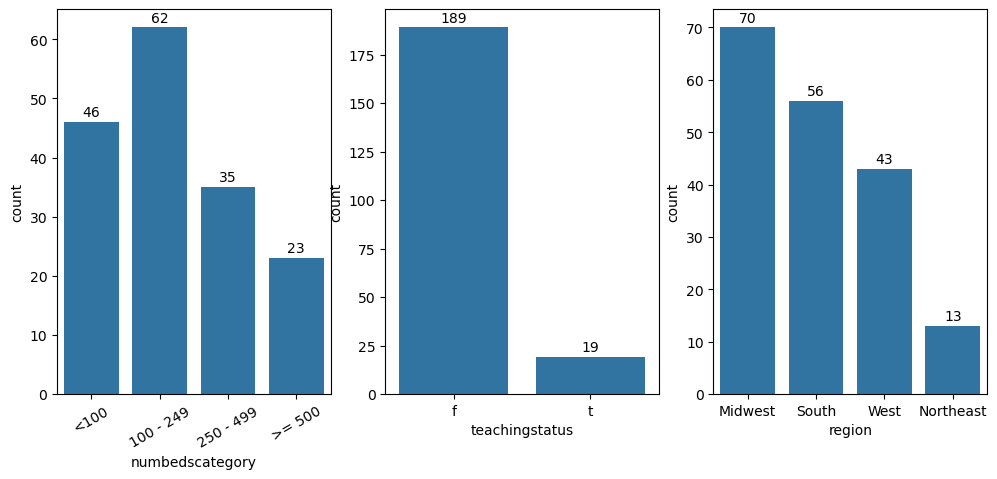

In [7]:
# Distribution of teaching hospitals, bed categories, and regions 
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 5))

bed_category_order = ['<100', '100 - 249', '250 - 499', '>= 500']

ax1 = sns.countplot(data=hospital_df, x='numbedscategory', ax=ax1, order=bed_category_order)
ax1.bar_label(ax1.containers[0], padding=2)
ax1.tick_params(axis='x', rotation=30)

ax2 = sns.countplot(data=hospital_df, x='teachingstatus', ax=ax2)
ax2.bar_label(ax2.containers[0], padding=2)

ax3 = sns.countplot(data=hospital_df, x='region', ax=ax3)
ax3.bar_label(ax3.containers[0], padding=2)

plt.show()

<Axes: xlabel='numbedscategory', ylabel='count'>

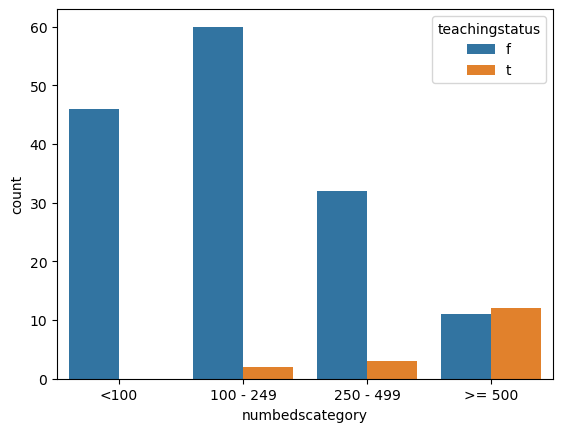

In [8]:
sns.countplot(data=hospital_df, x='numbedscategory', hue='teachingstatus', order=bed_category_order)

High proportions of largers hospitals are teaching hospitals. 

In [16]:
pd.crosstab(hospital_df['region'], hospital_df['numbedscategory'], dropna=False, margins=True)

numbedscategory,100 - 249,250 - 499,<100,>= 500,NaN,All
region,,,,,,
Midwest,23,6,20,8,13,70.0
Northeast,5,2,4,2,0,13.0
South,20,12,9,9,6,56.0
West,11,12,13,3,4,43.0
NaN,3,3,0,1,19,NaN
All,62,35,46,23,0,208.0


### Examining Missing Data Columns

In [9]:
!pip install missingno -q 

In [10]:
# Check if hospitals with missing region and numBedCategories are missing at random or they come from the same set of hospitals 
pd.crosstab(hospital_df['region'].isna(), hospital_df['numbedscategory'].isna())

numbedscategory,False,True
region,,
False,159,23
True,7,19


<Axes: >

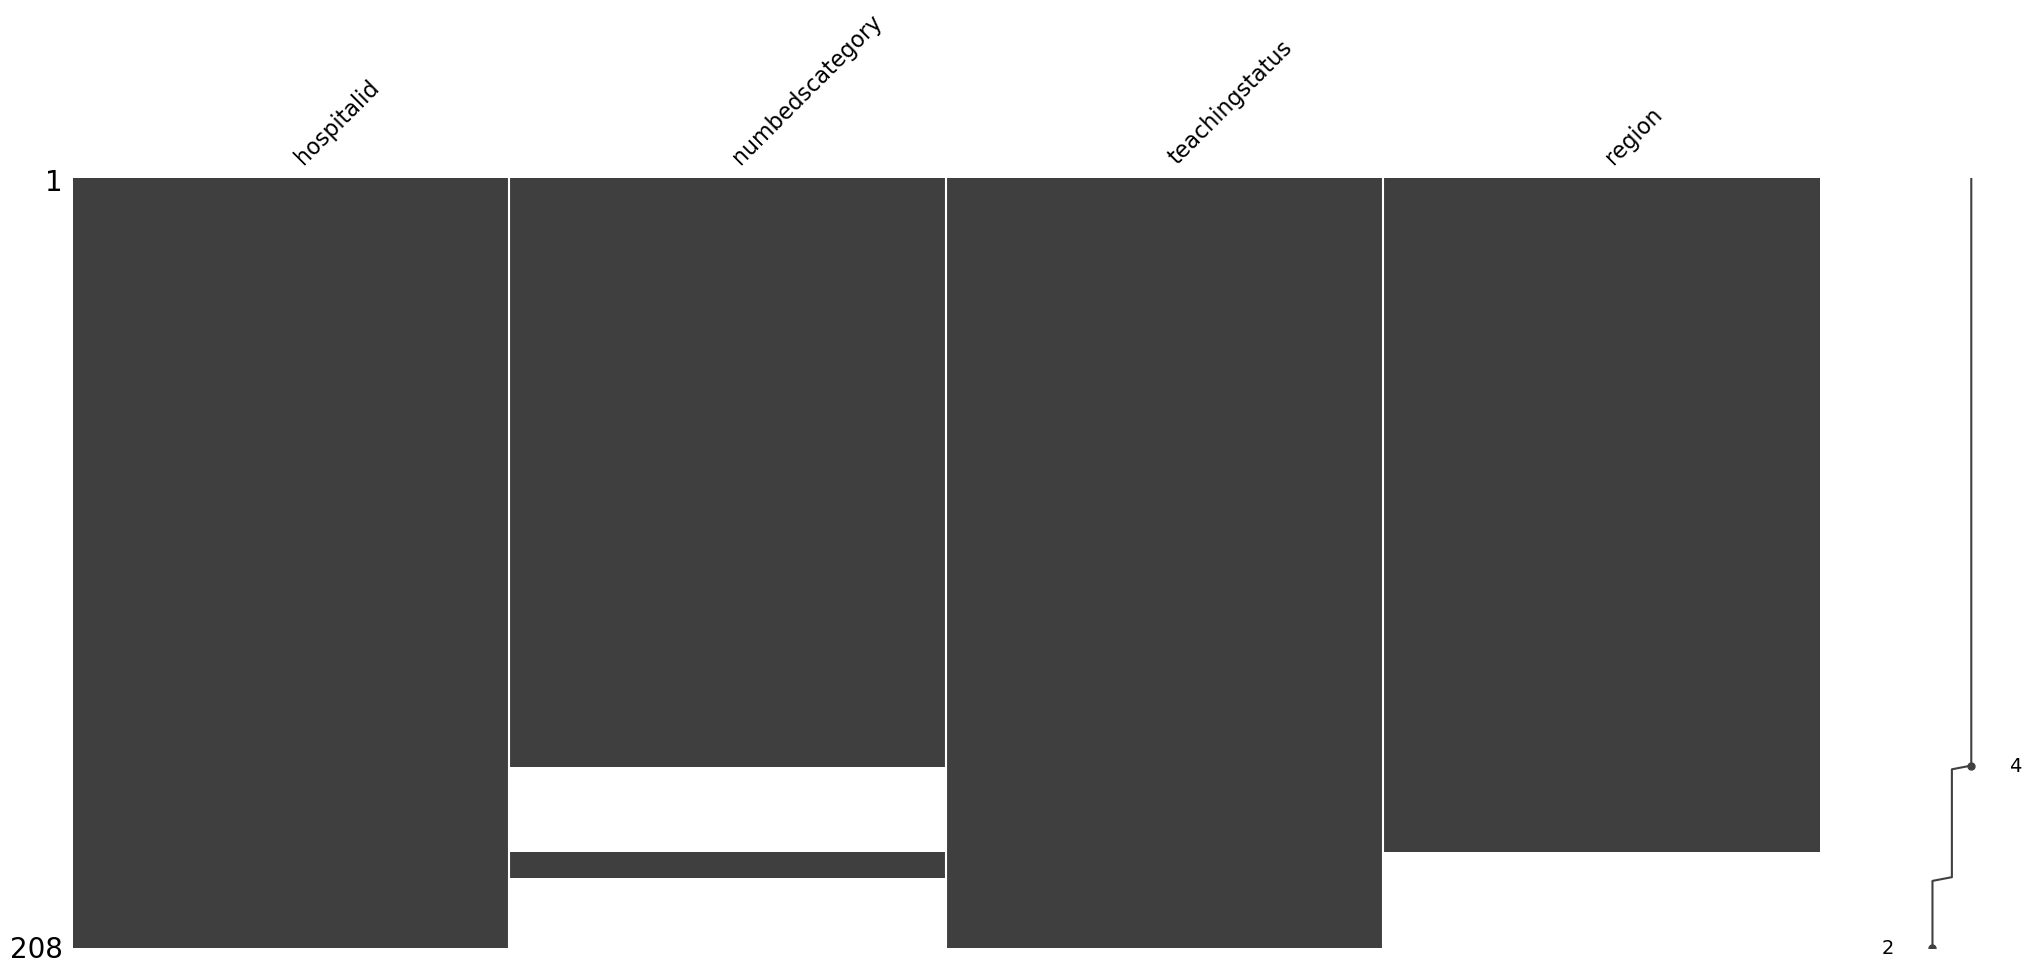

In [11]:
import missingno as msno
order = (hospital_df
         .assign(r=hospital_df['region'].isna(),
                 b=hospital_df['numbedscategory'].isna())
         .sort_values(['r', 'b'])
         .drop(columns=['r', 'b']))
msno.matrix(order)

It seems like the hospitals are not Missing Completely At Random, given 19 of the 42 hospitals with missing info have both missing 'numbedscategory' and 'region' data. 

The next step is to explore if the hospital with missing attributes tend to come from smaller hospitals. Since the size of the hospital is the missing attribute, the number of ICU stays per hospital will be used as a proxy for the hospital size. 

In [12]:
# Explore if missing hospitals tend to come from smaller hospitals 
stays = patient_df.groupby('hospitalid').size().rename('n_stays')
h = hospital_df.merge(stays, on='hospitalid', how='left')

In [13]:
h.groupby('numbedscategory', dropna=False)['n_stays'].agg(['count', 'median', 'mean'])

,count,median,mean
numbedscategory,,,
100 - 249,62,555.0,676.870968
250 - 499,35,1238.0,1306.171429
<100,46,246.0,273.760870
>= 500,23,3601.0,3274.130435
NaN,42,147.5,601.880952


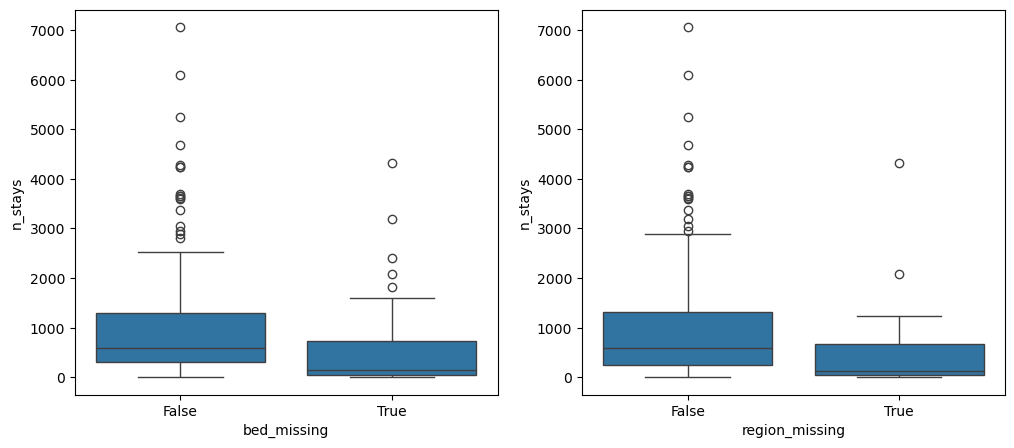

In [14]:
h['bed_missing'] = h['numbedscategory'].isna()
h['region_missing'] = h['region'].isna()


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1 = sns.boxplot(data=h, x='bed_missing', y='n_stays', ax=ax1)
ax2 = sns.boxplot(data=h, x='region_missing', y='n_stays', ax=ax2)
plt.show()

In [15]:
from scipy.stats import mannwhitneyu
print('p-val for missing numbedscategory and n_stays: ', mannwhitneyu(h.loc[h.bed_missing, 'n_stays'], h.loc[~h.bed_missing, 'n_stays']))
print('p-val for missing region and n_stays: ', mannwhitneyu(h.loc[h.region_missing, 'n_stays'], h.loc[~h.region_missing, 'n_stays']))

p-val for missing numbedscategory and n_stays:  MannwhitneyuResult(statistic=np.float64(2121.5), pvalue=np.float64(9.06602528047569e-05))
p-val for missing region and n_stays:  MannwhitneyuResult(statistic=np.float64(1399.5), pvalue=np.float64(0.0007656501542361265))


Hospitals with missing bed size or region tend to have fewer ICU stays than hospitals with complete information (Mann-Whitney U, p < 0.05 for both comparisons; also shown by the lower medians in the boxplots). Since ICU volume is a proxy for hospital size, this suggests the missing survey data is concentrated among smaller hospitals in the dataset, so the missingness is not completely at random.

In [16]:
both_missing = hospital_df['region'].isna() & hospital_df['numbedscategory'].isna()
no_missing_pt_rec = patient_df.loc[patient_df['hospitalid'].isin(hospital_df.loc[both_missing, 'hospitalid'])].shape[0]
print('No of patient records in the hospitals with both missing attributes: ', no_missing_pt_rec)
print('Percentage of the patient records in the hospitals with both missing attributes: ', 100 * no_missing_pt_rec/len(patient_df), '%')

No of patient records in the hospitals with both missing attributes:  8977
Percentage of the patient records in the hospitals with both missing attributes:  4.469304337868853 %


### ApachePatientResult EDA

Important note from the documentation: 

- Patients with an ICU stay less than 4 hours, most transplant patients, burn patients, and patients less than sixteen years of age will be classified as non-predictive (https://eicu.mit.edu/eicutables/apachepatientresult/). 

In [17]:
apr_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297064 entries, 0 to 297063
Data columns (total 23 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   apachepatientresultsid         297064 non-null  int64  
 1   patientunitstayid              297064 non-null  int64  
 2   physicianspeciality            297064 non-null  object 
 3   physicianinterventioncategory  297064 non-null  object 
 4   acutephysiologyscore           297064 non-null  int64  
 5   apachescore                    297064 non-null  int64  
 6   apacheversion                  297064 non-null  object 
 7   predictedicumortality          297064 non-null  float64
 8   actualicumortality             297064 non-null  object 
 9   predictediculos                297064 non-null  float64
 10  actualiculos                   297064 non-null  float64
 11  predictedhospitalmortality     297064 non-null  float64
 12  actualhospitalmortality       

#### ApacheVersion

In [18]:
apr_df['apacheversion'].unique()

array(['IV', 'IVa'], dtype=object)

In [19]:
apr_df.groupby('apacheversion').size()

apacheversion
IV     148532
IVa    148532
dtype: int64

#### Explore Distribution of Apache Predictions

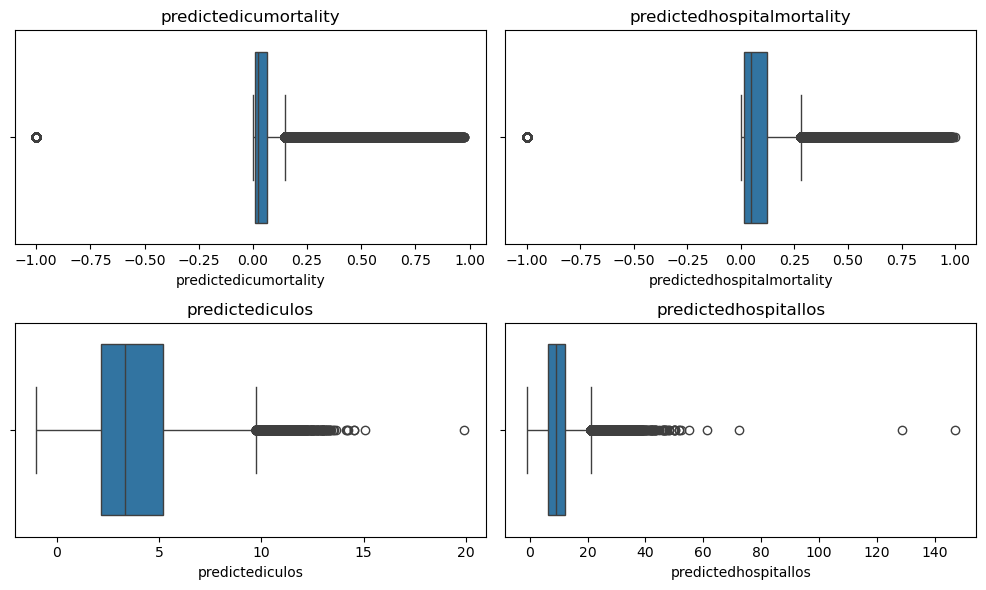

In [20]:
# Use the IVa version only for the rest of the analysis 
apr2_df = apr_df[apr_df['apacheversion']=='IVa']

# Check the distribution of predictedicumortality, predictedhospitalmortality, predictediculos, predictedhospitallos
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes = axes.flatten()

apache_cols = ['predictedicumortality', 'predictedhospitalmortality', 'predictediculos', 'predictedhospitallos']

for ax, col in zip(axes, apache_cols):
    sns.boxplot(x=apr2_df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [21]:
# Summary stats 
for col in apache_cols:
    print(apr2_df[col].describe())

count    148532.000000
mean          0.041830
std           0.227042
min          -1.000000
25%           0.008792
50%           0.023008
75%           0.064422
max           0.974649
Name: predictedicumortality, dtype: float64
count    148532.000000
mean          0.025555
std           0.346418
min          -1.000000
25%           0.016426
50%           0.045743
75%           0.121703
max           0.998138
Name: predictedhospitalmortality, dtype: float64
count    148532.000000
mean          3.814601
std           2.317528
min          -1.000000
25%           2.171884
50%           3.348648
75%           5.198296
max          19.907512
Name: predictediculos, dtype: float64
count    148532.000000
mean          9.314339
std           5.448849
min          -1.000000
25%           6.275243
50%           9.124434
75%          12.222766
max         146.937410
Name: predictedhospitallos, dtype: float64


It seems that -1 is used as a sentinel value to flag as non-predicted.

Checking how mnay rows are flagged as non-predicted from the dataset:

In [39]:
lst1 = apr2_df[apr2_df['predictedicumortality']==-1.0].apachepatientresultsid
lst2 = apr2_df[apr2_df['predictedhospitalmortality']==-1.0].apachepatientresultsid
lst3 = apr2_df[apr2_df['predictediculos']==-1.0].apachepatientresultsid
lst4 = apr2_df[apr2_df['predictedhospitallos']==-1.0].apachepatientresultsid

print(len(lst1))
print(len(lst2))
print(len(lst3))
print(len(lst4))
print(sum(lst1==lst3))
print(sum(lst2==lst4))

4487
12296
4487
12296
4487
12296


From the above, the 4,487 stays missing ICU mortality are the same rows missing ICU LOS; same for the 12,296 hospital rows. And there are more missing predictions at the hospital level than at the ICU level. 

In [40]:
# Check if the ICU-missing set is subset of the hospital-missing set
print(set(lst1).issubset(set(lst3))) 

# Repeat ICU stays within one hospitalisation
m = apr2_df.merge(patient_df[['patientunitstayid', 'unitvisitnumber', 'hospitaldischargestatus']], on='patientunitstayid')
m['hosp_missing'] = m.predictedhospitalmortality == -1
print(pd.crosstab(m.unitvisitnumber.clip(upper=6), m.hosp_missing, normalize='index'))

True
hosp_missing        False     True 
unitvisitnumber                    
1                0.975938  0.024062
2                0.533499  0.466501
3                0.154745  0.845255
4                0.075080  0.924920
5                0.028340  0.971660
6                0.012579  0.987421


This suggests that hospital prediction is not assigned by the APACHE model for repeated ICU stays within a hospitalisation, eliminating potential double-counting problems for the hospital O/E analysis to follow. 


#### Exploration of Prediction Coverage by Hospital
- What fraction of each hospital's ICU stays have an APACHE prediction at all?

In [23]:
cov = (patient_df[['patientunitstayid', 'hospitalid']]
       .merge(apr2_df[['patientunitstayid', 'predictedhospitalmortality']],
              on='patientunitstayid', how='left')
       .assign(scored=lambda d: d.predictedhospitalmortality.notna()
                               & (d.predictedhospitalmortality != -1))
       .groupby('hospitalid')['scored'].agg(n_stays='size', pct_scored='mean')
       .sort_values('pct_scored'))

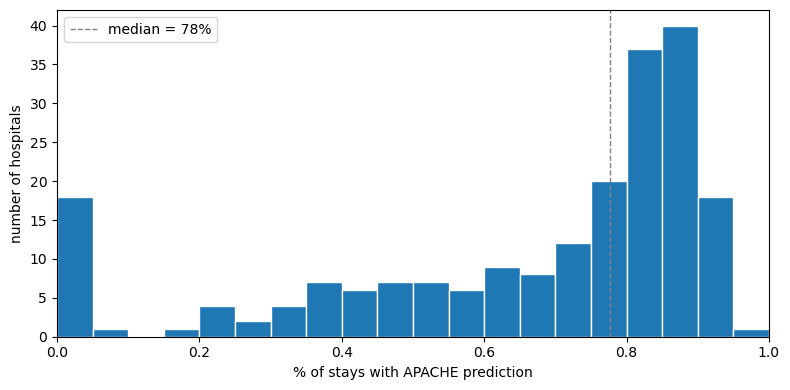

In [24]:
# Plot the distribution of APACHE coverage percentage 
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cov.pct_scored, bins=np.arange(0, 1.05, 0.05), edgecolor='white')
ax.axvline(cov.pct_scored.median(), ls='--', c='grey', lw=1,
           label=f'median = {cov.pct_scored.median():.0%}')
ax.set_xlabel('% of stays with APACHE prediction')
ax.set_ylabel('number of hospitals')
ax.set_xlim(0, 1)
ax.legend()
plt.tight_layout()

In [26]:
print('No. hospitals with no APACHE coverage:', len(cov[cov['pct_scored'] == 0]))

No. hospitals with no APACHE coverage: 18


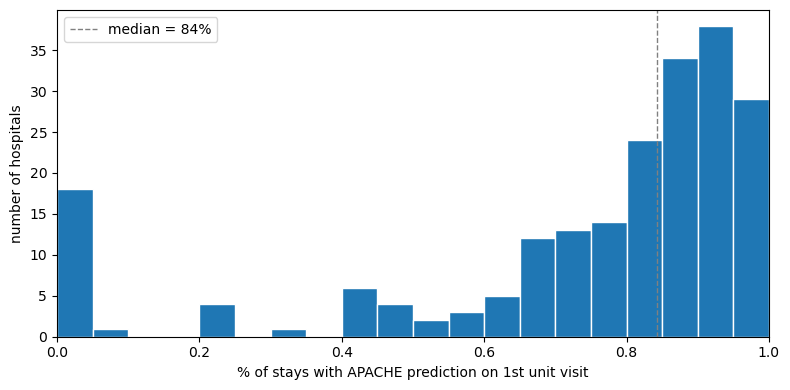

In [27]:
# Recompute hospital-mortality prediction coverage using first ICU visits only
cov_hosp = (patient_df.loc[patient_df.unitvisitnumber == 1, ['patientunitstayid', 'hospitalid']]
            .merge(apr2_df[['patientunitstayid', 'predictedhospitalmortality']],
                   on='patientunitstayid', how='left')
            .assign(scored=lambda d: d.predictedhospitalmortality.notna()
                                    & (d.predictedhospitalmortality != -1))
            .groupby('hospitalid')['scored'].agg(n_stays='size', pct_scored='mean'))

# plot again
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cov_hosp.pct_scored, bins=np.arange(0, 1.05, 0.05), edgecolor='white')
ax.axvline(cov_hosp.pct_scored.median(), ls='--', c='grey', lw=1,
           label=f'median = {cov_hosp.pct_scored.median():.0%}')
ax.set_xlabel('% of stays with APACHE prediction on 1st unit visit')
ax.set_ylabel('number of hospitals')
ax.set_xlim(0, 1)
ax.legend()
plt.tight_layout()

From the diagrams above, 0.4 seems like a natural threshold as hospitals below this threshold were sparse and separated by gaps, while there is a continuous distribution above this threshold. 
We thereby exclude hospitals with less than 40% coverage from the benchmarking since O/E at such hospitals would describe only a small and possibly unrepresentative subset of their patients.

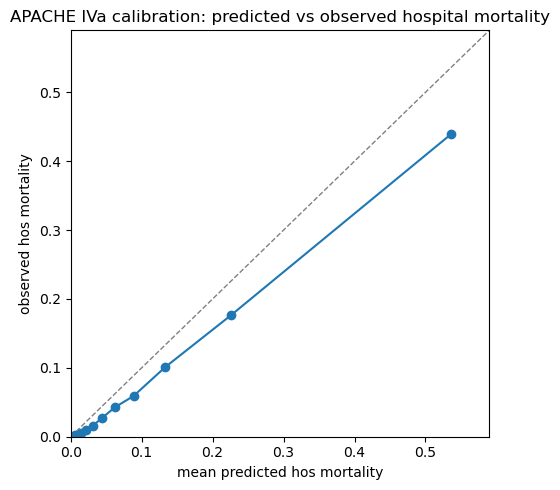

In [88]:
# Using 0.4 as the threshold, and limiting to the 1st visit for hospital mortality 
hosp_keep = cov_hosp[cov_hosp.pct_scored >= 0.4].index

cal = (patient_df.loc[patient_df.unitvisitnumber == 1,
                      ['patientunitstayid', 'hospitalid']]
       .merge(apr2_df[['patientunitstayid', 'predictedhospitalmortality',
                       'actualhospitalmortality']], on='patientunitstayid')
       .query('hospitalid in @hosp_keep'))

cal['pred'] = pd.to_numeric(cal.predictedhospitalmortality, errors='coerce')
# dropping the missing rows with filled in sentinel value 
cal = cal[cal.pred >= 0]                      

cal.actualhospitalmortality.value_counts()    
cal['died'] = (cal.actualhospitalmortality == 'EXPIRED').astype(int)


cal['bin'] = pd.qcut(cal.pred, 10)
tab = cal.groupby('bin', observed=True).agg(pred=('pred', 'mean'), obs=('died', 'mean'), n=('died', 'size'))

# Plot observed to hospital predicted mortality 
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], ls='--', c='grey', lw=1)
ax.plot(tab.pred, tab.obs, marker='o')
ax.set_xlabel('mean predicted hos mortality')
ax.set_ylabel('observed hos mortality')
ax.set_xlim(0, tab.pred.max() * 1.1)
ax.set_ylim(0, tab.pred.max() * 1.1)
ax.set_title('APACHE IVa calibration: predicted vs observed hospital mortality')
plt.tight_layout()

In [29]:
print(cal.died.sum() / cal.pred.sum())

0.7550842911277504


### Calculate the hopistal O/E per hospital 

In [42]:
cal.head()

,patientunitstayid,hospitalid,predictedhospitalmortality,actualhospitalmortality,pred,died,bin
0,141168,59,0.059099,EXPIRED,0.059099,1,"(0.052, 0.0734]"
1,141194,73,0.102283,ALIVE,0.102283,0,"(0.0734, 0.107]"
2,141203,66,0.470973,ALIVE,0.470973,0,"(0.311, 0.998]"
3,141208,73,0.002249,ALIVE,0.002249,0,"(-0.000581, 0.0103]"
4,141227,60,0.488562,ALIVE,0.488562,0,"(0.311, 0.998]"


In [52]:
hosp = cal.groupby('hospitalid').agg(O=('died', 'sum'), E=('pred', 'sum'), n=('died', 'size'))
hosp['oe'] = hosp['O'] / hosp['E']

In [53]:
target = hosp.O.sum() / hosp.E.sum()
print(target)

0.7550842911277507


In [54]:
hosp = hosp.sort_values(by='n', ascending=True)
hosp.head(10).style.hide(axis='index')

O,E,n,oe
0,0.010421,2,0.000000
0,0.851191,7,0.000000
0,0.528824,8,0.000000
0,1.410580,8,0.000000
0,1.710099,10,0.000000
1,1.395460,11,0.716609
2,1.628868,12,1.227846
0,0.769496,13,0.000000
1,1.663680,18,0.601077
4,1.992721,26,2.007306


From the table above, it can be seen that there are some small hospitals whose O/E would vary significantly had the number of deaths changed by 1. To reduce noise, only larger hospitals with E >= 5 will be included in subsequent analysis. 

In [55]:
hosp_reduced = hosp[hosp['E'] >= 5] 
print('No. hosp removed:', len(hosp) - len(hosp_reduced))

No. hosp removed: 16


Assuming patient deaths occur independently and are relatively rare, the no. of deaths at a hospital will be modelled as a Poisson count with mean equal to the cohort O/E (0.755) multiplied by its expected deaths. 

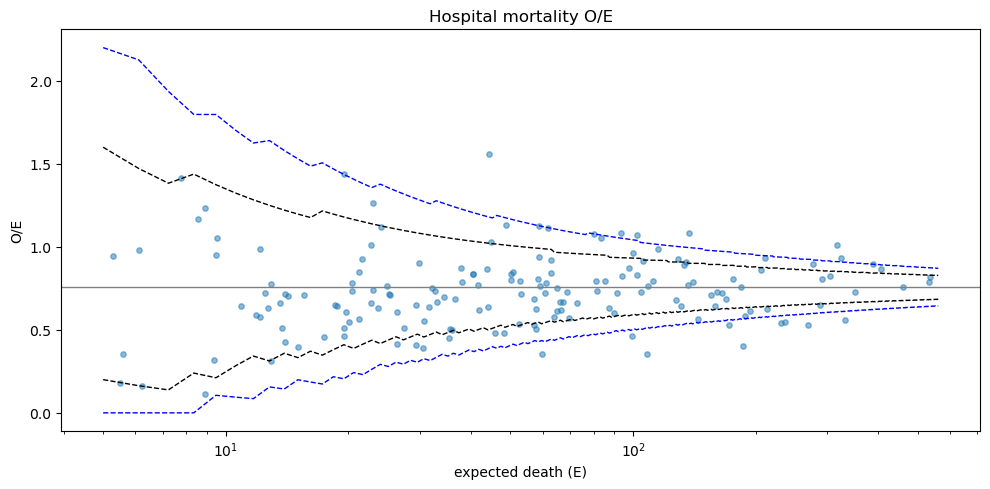

In [78]:
from scipy.stats import poisson

grid = np.linspace(5, hosp_reduced['E'].max() * 1.05, 500)
m = target * grid 

low95 = poisson.ppf(0.025, m) / grid
high95 = poisson.ppf(0.975, m) / grid 
low998 = poisson.ppf(0.001, m) / grid
high998 = poisson.ppf(0.999, m) / grid

# plot the funnel plot 
# scatter plot 
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(hosp_reduced['E'], hosp_reduced['oe'], s=15, alpha=0.5)
ax.axhline(target, c='grey', lw=1)

# add the funnel lines 
ax.plot(grid, low95, c='black', ls='--', lw=1)
ax.plot(grid, high95, c='black', ls='--', lw=1)
ax.plot(grid, low998, c='blue', ls='--', lw=1)
ax.plot(grid, high998, c='blue', ls='--', lw=1)

ax.set_xscale('log')
ax.set_xlabel('expected death (E)')
ax.set_ylabel('O/E')
ax.set_title('Hospital mortality O/E')
plt.tight_layout()

From the diagram above, 14 hospitals are outside the 99.8% , when about 0.3 (=0.002 * 168) ~= 0 hospitals are expected to be outside this line. The observed variance seems to be greater than the expected variance. We investigate the overdispersion below. 

In [72]:
# Investigating overdispersion
hosp_reduced['z'] = (hosp_reduced.oe - target) / np.sqrt(target / hosp_reduced.E)

zw = hosp_reduced.z.clip(hosp_reduced.z.quantile(0.1), hosp_reduced.z.quantile(0.9))
phi = (zw ** 2).mean()
print(phi)

2.187083168319961


Phi = 2.18... > 1. Overdispersion is indeed present. We next adjust for this. 

In [76]:
# Adjusting for overdispersion
se = np.sqrt(phi * target / hosp_reduced.E)
hosp_reduced['lo_adj'] = target - 3.09 * se # using the 99.8% zp = 3.09 from the normal distribution
hosp_reduced['hi_adj'] = target + 3.09 * se
hosp_reduced['category'] = np.select([hosp_reduced.oe > hosp_reduced.hi_adj, hosp_reduced.oe < hosp_reduced.lo_adj], ['high', 'low'], default='within')
print(hosp_reduced.category.value_counts())

category
within    164
high        2
low         2
Name: count, dtype: int64


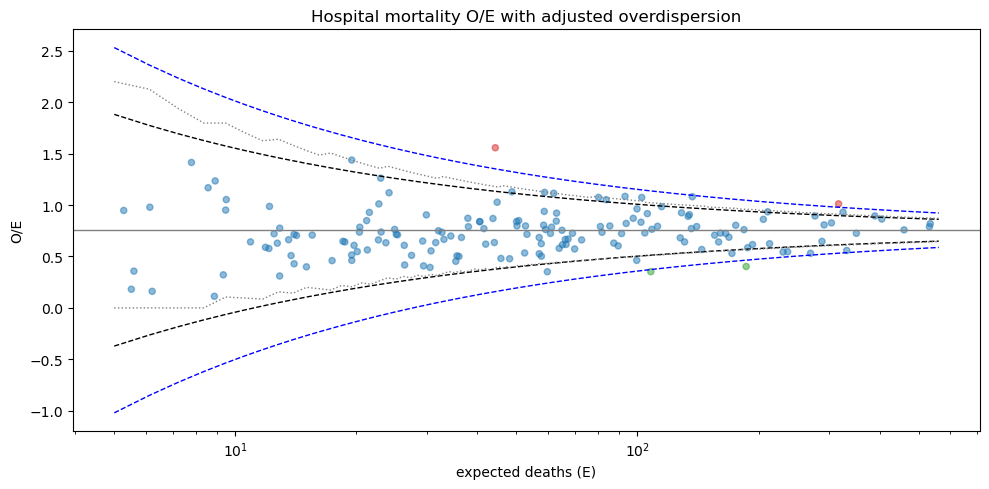

In [79]:
# Re-plot the funnel plot, adjusted for overdispersion
se_line = np.sqrt(phi * target / grid)
colours = hosp_reduced.category.map({'high': 'tab:red', 'low': 'tab:green', 'within': 'tab:blue'})

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(hosp_reduced.E, hosp_reduced.oe, s=20, alpha=0.5, c=colours)
ax.axhline(target, c='grey', lw=1)

ax.plot(grid, target + 1.96 * se_line, c='black', ls='--', lw=1)
ax.plot(grid, target - 1.96 * se_line, c='black', ls='--', lw=1)
ax.plot(grid, target + 3.09 * se_line, c='blue', ls='--', lw=1)
ax.plot(grid, target - 3.09 * se_line, c='blue', ls='--', lw=1)

ax.plot(grid, high998, c='grey', ls=':', lw=1)
ax.plot(grid, low998, c='grey', ls=':', lw=1)

ax.set_xscale('log')
ax.set_xlabel('expected deaths (E)')
ax.set_ylabel('O/E')
ax.set_title('Hospital mortality O/E with adjusted overdispersion')
plt.tight_layout()

#### Investigating the 4 outliers 

In [ ]:
outliers = hosp_reduced[hosp_reduced['category'] != 'within']

In [85]:
out = hosp_f[hosp_f.flag_adj != 'within'].index

prof = (hosp_f.loc[out, ['flag_adj', 'n', 'E', 'O', 'oe']]
        .join(hospital_df.set_index('hospitalid')[['teachingstatus', 'numbedscategory', 'region']])
        .join(cov_hosp['pct_scored']))

# accounting for coverage percentage, apache score and admission from other hospitals
pt = patient_df[patient_df.unitvisitnumber == 1]
pt = pt.merge(apr2_df[['patientunitstayid', 'apachescore']], on='patientunitstayid', how='left')
prof = prof.join(pt.groupby('hospitalid')['apachescore'].median().rename('median_apache'))
prof = prof.join(pt.groupby('hospitalid')['unitadmitsource'].apply(lambda s: s.eq('Other Hospital').mean()).rename('pct_from_other_hosp'))

Across APACHE coverage, median APACHE score and the share of admissions from other hospitals, none of the four outliers stood out. No explanatory factors can therefore be found for their results.